# Module 2 · Partie 5 : Comparaison des modèles et validation externe

> *Multivaried Analysis 2 : Data Mining & Machine Learning*, Prof. Hélène Soyeurt, ULiège Gembloux Agro-Bio Tech, 2026-2027
> Sources : exercice dirigé officiel `PLS_PCR_fatty_acids_20201007.Rmd` (§5, §6 et §7), syllabus *Validation, PCR and PLS* (§1 et §3.5).

**Objectifs d'apprentissage**

À la fin de ce notebook, tu sauras :

1. choisir le paramètre λ des régressions pénalisées (module 1) par **validation croisée** avec `cv.glmnet()` et interpréter `lambda.min` et `lambda.1se` ;
2. appliquer des modèles PCR, PLS, Ridge, Lasso et Elastic Net à un **jeu de validation externe** indépendant (`predict()` pour chaque type d'objet) ;
3. calculer et interpréter les indicateurs de validation : **R²**, **RMSEP**, **biais**, **SEP**, **RPD** ;
4. vérifier, avec la **distance GH**, que les échantillons à prédire sont dans le domaine de calibration (syllabus §3.5) ;
5. tester l'effet de la suppression des **régions spectrales bruitées** ;
6. repérer et corriger les erreurs de l'exercice dirigé officiel.

**Prérequis** : parties 1 (validation), 2 (ACP, GH), 3 (PCR), 4 (PLS) et module 1, partie 6 (Ridge, Lasso, Elastic Net, `glmnet`).

**Sommaire**

- 5.0 Préparation : données, nettoyage GH, modèles PCR et PLS
- 5.1 Régressions pénalisées avec validation croisée : `cv.glmnet()`
- 5.2 Validation externe sur un jeu indépendant
- 5.3 Le domaine de prédiction : GH des échantillons à prédire
- 5.4 Suppression des régions spectrales bruitées
- 5.5 Synthèse : PCR, PLS ou régression pénalisée ?
- Questions de compréhension
- Récapitulatif

## 5.0 Préparation : données, nettoyage GH, modèles PCR et PLS

On reconstruit ici, pour que le notebook soit **autonome**, tous les objets de l'exercice dirigé :

1. lecture de `fatty_acids.csv` (485 échantillons, SAT en g/dl de lait, 1 060 points spectraux MIR) ;
2. nettoyage des outliers spectraux : ACP (47 CP = 99 % de la variabilité), **GH = D² / 47**, on garde GH < 3 (partie 2) ;
3. modèles **PCR** et **PLS** avec 70 composantes et validation croisée 10-fold (parties 3 et 4).

Cette cellule prend une minute environ (la PCR à 70 composantes est la plus longue).

In [1]:
suppressPackageStartupMessages({
  library(pls)
  library(FactoMineR)
  library(glmnet)
  library(summarytools)
  library(knitr)
})
options(repr.plot.width = 10, repr.plot.height = 6)

fattyacid <- read.table(file = "../fatty_acids.csv", sep = ";", header = TRUE)
x <- fattyacid[, 5:1064]       # spectre
y <- fattyacid[, 2]            # SAT

# Outliers spectraux : distance GH sur 47 composantes principales
res.pca <- PCA(x, scale.unit = TRUE, ncp = 47, graph = FALSE)
coordPC <- res.pca$ind$coord
GH <- mahalanobis(coordPC, center = colMeans(coordPC), cov = cov(coordPC)) / 47
newX <- x[GH < 3, ]; newy <- y[GH < 3]
c(n_calibration = length(newy), retirés = sum(GH >= 3))

n_calibration       retirés 
          482             3

In [2]:
calibration <- data.frame(newy, newX)
names(calibration) <- c("SAT", paste0("SPEC", 1:1060))

set.seed(1001)
PCR <- pcr(SAT ~ ., data = calibration, scale = TRUE, center = TRUE, validation = "CV", ncomp = 70)
set.seed(1001)
PLS <- plsr(SAT ~ ., data = calibration, method = "oscorespls", scale = TRUE, center = TRUE,
            validation = "CV", ncomp = 70)

# Rappel : performances de validation croisée des modèles retenus (parties 3 et 4)
rmse_cv <- function(mod, k) RMSEP(mod, estimate = "CV")$val[1, 1, k + 1]
r2_cv   <- function(mod, k) R2(mod, estimate = "CV")$val[1, 1, k + 1]
round(rbind(PCR_10 = c(R2cv = r2_cv(PCR, 10), RMSEcv = rmse_cv(PCR, 10)),
            PLS_11 = c(R2cv = r2_cv(PLS, 11), RMSEcv = rmse_cv(PLS, 11))), 4)

,R2cv,RMSEcv
PCR_10,0.9221,0.2379
PLS_11,0.9626,0.1650


On retrouve les valeurs de l'exercice dirigé : PCR à 10 composantes (R²cv = 92.2 %, RMSEcv = 0.238 g/dl) et PLS à 11 variables latentes (R²cv = 96.3 %, RMSEcv = 0.165 g/dl).

---
## 5.1 Régressions pénalisées avec validation croisée : `cv.glmnet()`

### 5.1.1 Rappel et principe

Au module 1, on a vu les régressions **Ridge** (pénalité L2, `alpha = 0`), **Lasso** (pénalité L1, `alpha = 1`) et **Elastic Net** (mélange, ici `alpha = 0.5`). Le paramètre λ y était choisi sur **un** jeu de validation. Avec le module 2, on dispose d'un meilleur outil : la **validation croisée k-fold** (partie 1). La fonction `cv.glmnet()` l'automatise : pour chaque valeur de λ, elle calcule l'erreur moyenne de prédiction sur les k segments.

> **Fonction R** : `cv.glmnet(x, y, alpha = 1, lambda = NULL, nfolds = 10, type.measure = "mse", standardize = TRUE, family = "gaussian", ...)`
>
> | Sortie | Contenu |
> |---|---|
> | `$lambda` | valeurs de λ testées (**triées par ordre décroissant**) |
> | `$cvm` | erreur moyenne de validation croisée pour chaque λ (ici le **MSE** : $\sqrt{cvm}$ = RMSEcv) |
> | `$cvsd` | écart-type (erreur standard) de cette erreur entre les segments |
> | `$cvup`, `$cvlo` | `cvm + cvsd` et `cvm - cvsd` (bande d'incertitude) |
> | `$nzero` | nombre de coefficients non nuls (variables sélectionnées) pour chaque λ |
> | `$lambda.min` | λ qui donne la **plus petite** erreur moyenne |
> | `$lambda.1se` | **plus grand** λ dont l'erreur est à moins d'**une erreur standard** du minimum (modèle plus parcimonieux) |
> | `$glmnet.fit` | le modèle `glmnet` ajusté sur **toutes** les données (chemin complet) |
>
> `x` doit être une **matrice** (`as.matrix()`). Prédire : `predict(cvfit, newx = ..., s = "lambda.1se")` (ou une valeur numérique de λ).

> **Définition** : la **règle d'une erreur standard** (*one standard error rule*) consiste à préférer, parmi les modèles dont l'erreur n'est pas significativement plus grande que le minimum (à moins d'une erreur standard), le **plus simple**. Pour glmnet, c'est le plus grand λ, donc la pénalité la plus forte. C'est la même idée que `selectNcomp(..., "onesigma")` pour la PLS (partie 4).

### 5.1.2 Les trois modèles de l'exercice dirigé

On utilise la grille de λ du Rmd. Le même `set.seed(1001)` avant chaque modèle garantit le même découpage en segments.

In [3]:
grid <- c(10, 1, 0.1, 0.01, 0.001, 0.0001, 0.00001)
Xcal <- as.matrix(newX)
set.seed(1001)
Ridge <- cv.glmnet(x = Xcal, y = newy, standardize = TRUE, alpha = 0, lambda = grid, family = "gaussian")
set.seed(1001)
Lasso <- cv.glmnet(x = Xcal, y = newy, standardize = TRUE, alpha = 1, lambda = grid, family = "gaussian")
set.seed(1001)
Elastic <- cv.glmnet(x = Xcal, y = newy, standardize = TRUE, alpha = 0.5, lambda = grid, family = "gaussian")
Lasso


Call:  cv.glmnet(x = Xcal, y = newy, lambda = grid, standardize = TRUE,      alpha = 1, family = "gaussian") 

Measure: Mean-Squared Error 

    Lambda Index  Measure        SE Nonzero
min  1e-05     7 0.009838 0.0009133     881
1se  1e-04     6 0.010424 0.0010860     488

L'exercice dirigé rassemble tous les résultats dans un grand tableau (7 lignes par modèle). On écrit une petite fonction qui fait la même chose de façon plus lisible :

In [4]:
tab_cv <- function(m) data.frame(lambda = m$lambda, MSEcv = m$cvm, SD_MSEcv = m$cvsd,
                                 Max_MSEcv = m$cvup, Min_MSEcv = m$cvlo,
                                 Nvariables = m$nzero, RMSEcv = sqrt(m$cvm), row.names = NULL)
dg <- c(5, 4, 4, 4, 4, 0, 4)   # nombre de décimales par colonne (5 pour lambda, sinon 1e-05 s'affiche 0)
kable(tab_cv(Ridge), digits = dg, align = "c", caption = "Ridge")
kable(tab_cv(Lasso), digits = dg, align = "c", caption = "Lasso")
kable(tab_cv(Elastic), digits = dg, align = "c", caption = "Elastic Net (alpha = 0.5)")



Table: Ridge

| lambda | MSEcv  | SD_MSEcv | Max_MSEcv | Min_MSEcv | Nvariables | RMSEcv |
|:------:|:------:|:--------:|:---------:|:---------:|:----------:|:------:|
| 1e+01  | 0.0561 |  0.0065  |  0.0625   |  0.0496   |    1060    | 0.2368 |
| 1e+00  | 0.0352 |  0.0040  |  0.0392   |  0.0312   |    1060    | 0.1877 |
| 1e-01  | 0.0237 |  0.0021  |  0.0259   |  0.0216   |    1060    | 0.1540 |
| 1e-02  | 0.0143 |  0.0013  |  0.0156   |  0.0130   |    1060    | 0.1194 |
| 1e-03  | 0.0136 |  0.0013  |  0.0149   |  0.0123   |    1060    | 0.1166 |
| 1e-04  | 0.0135 |  0.0013  |  0.0148   |  0.0122   |    1060    | 0.1161 |
| 1e-05  | 0.0135 |  0.0013  |  0.0148   |  0.0122   |    1060    | 0.1160 |



Table: Lasso

| lambda | MSEcv  | SD_MSEcv | Max_MSEcv | Min_MSEcv | Nvariables | RMSEcv |
|:------:|:------:|:--------:|:---------:|:---------:|:----------:|:------:|
| 1e+01  | 0.7284 |  0.0678  |  0.7963   |  0.6606   |     0      | 0.8535 |
| 1e+00  | 0.7284 |  0.0678  |  0.7963   |  0.6606   |     0      | 0.8535 |
| 1e-01  | 0.0495 |  0.0056  |  0.0551   |  0.0438   |     9      | 0.2224 |
| 1e-02  | 0.0298 |  0.0032  |  0.0330   |  0.0267   |     30     | 0.1727 |
| 1e-03  | 0.0138 |  0.0015  |  0.0154   |  0.0123   |    108     | 0.1175 |
| 1e-04  | 0.0104 |  0.0011  |  0.0115   |  0.0093   |    488     | 0.1021 |
| 1e-05  | 0.0098 |  0.0009  |  0.0108   |  0.0089   |    881     | 0.0992 |



Table: Elastic Net (alpha = 0.5)

| lambda | MSEcv  | SD_MSEcv | Max_MSEcv | Min_MSEcv | Nvariables | RMSEcv |
|:------:|:------:|:--------:|:---------:|:---------:|:----------:|:------:|
| 1e+01  | 0.7284 |  0.0678  |  0.7963   |  0.6606   |     0      | 0.8535 |
| 1e+00  | 0.3139 |  0.0344  |  0.3483   |  0.2795   |     24     | 0.5602 |
| 1e-01  | 0.0390 |  0.0042  |  0.0432   |  0.0347   |     32     | 0.1974 |
| 1e-02  | 0.0271 |  0.0026  |  0.0297   |  0.0245   |     62     | 0.1646 |
| 1e-03  | 0.0109 |  0.0011  |  0.0120   |  0.0098   |    164     | 0.1046 |
| 1e-04  | 0.0094 |  0.0011  |  0.0105   |  0.0084   |    571     | 0.0972 |
| 1e-05  | 0.0092 |  0.0010  |  0.0103   |  0.0082   |    909     | 0.0962 |

> **Attention** : dans le Rmd, la ligne `sqrt(cvm)` est intitulée « mean RMSEcv » au §5 et les lignes `cvm` sont appelées « mean RMSEcv » au §7. C'est faux : `cvm` est un **MSE** (erreur au carré), seule sa racine est un RMSE.

In [5]:
# Récapitulatif lambda.min / lambda.1se (tableau de l'exercice dirigé)
lam <- function(m, nom) data.frame(Model = nom,
  Lambda.min = m$lambda.min, Var.min = m$nzero[m$lambda == m$lambda.min],
  Lambda.1se = m$lambda.1se, Var.1se = m$nzero[m$lambda == m$lambda.1se])
kable(rbind(lam(Ridge, "Ridge"), lam(Lasso, "Lasso"), lam(Elastic, "ElasticNet")),
      align = "c", row.names = FALSE)



|   Model    | Lambda.min | Var.min | Lambda.1se | Var.1se |
|:----------:|:----------:|:-------:|:----------:|:-------:|
|   Ridge    |   1e-05    |  1060   |   1e-02    |  1060   |
|   Lasso    |   1e-05    |   881   |   1e-04    |   488   |
| ElasticNet |   1e-05    |   909   |   1e-04    |   571   |

On retrouve le tableau du Rmd :

- **Ridge** : 1 060 variables quel que soit λ (Ridge ne met jamais de coefficient exactement à 0) ;
- **Lasso** : 881 variables avec `lambda.min`, **488** avec `lambda.1se` ;
- **Elastic Net** : 909 variables avec `lambda.min`, 571 avec `lambda.1se`.

`lambda.min` tombe sur la **plus petite** valeur de la grille (1e-05) : la grille ne permet pas de savoir si l'erreur continuerait à baisser en dessous. C'est le même problème que le minimum de la PLS atteint à 70 composantes (partie 4).

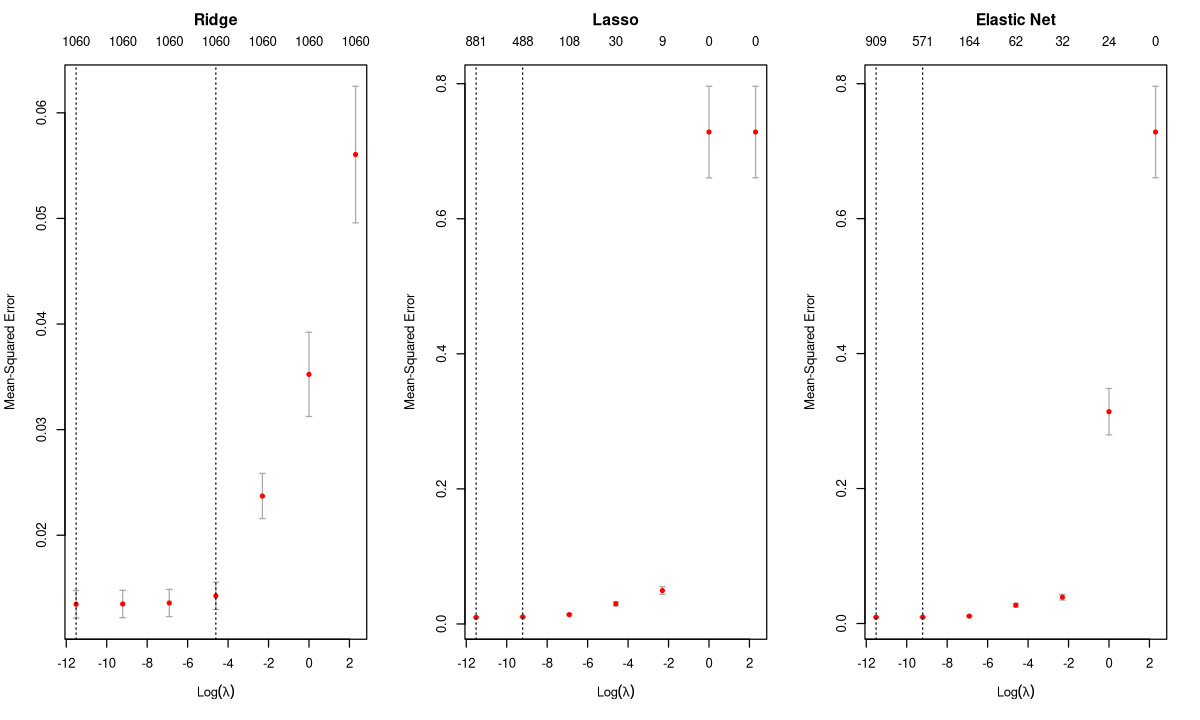

In [6]:
par(mfrow = c(1, 3))
plot(Ridge, sign.lambda = 1); title("Ridge", line = 2.5)      # sign.lambda = 1 : axe log(lambda)
plot(Lasso, sign.lambda = 1); title("Lasso", line = 2.5)
plot(Elastic, sign.lambda = 1); title("Elastic Net", line = 2.5)
par(mfrow = c(1, 1))

Lecture du graphe de `plot(cv.glmnet)` : en abscisse $\log(\lambda)$ (avec `sign.lambda = 1` ; par défaut, glmnet 5.x affiche $-\log(\lambda)$ et inverse donc le sens de lecture), en ordonnée le MSE de validation croisée avec sa barre d'erreur ($\pm$ `cvsd`) ; en haut, le nombre de variables non nulles ; les deux traits verticaux pointillés indiquent `lambda.min` (à gauche) et `lambda.1se`.

### 5.1.3 Comparaison des erreurs de validation croisée

In [7]:
cv_tab <- data.frame(
  Modele = c("PCR (10 CP)", "PLS (11 VL)", "Ridge (1se)", "Lasso (1se)", "Elastic Net (1se)"),
  Nb_param = c(10, 11, Ridge$nzero[Ridge$lambda == Ridge$lambda.1se],
               Lasso$nzero[Lasso$lambda == Lasso$lambda.1se], Elastic$nzero[Elastic$lambda == Elastic$lambda.1se]),
  RMSEcv = c(rmse_cv(PCR, 10), rmse_cv(PLS, 11),
             sqrt(Ridge$cvm[Ridge$lambda == Ridge$lambda.1se]),
             sqrt(Lasso$cvm[Lasso$lambda == Lasso$lambda.1se]),
             sqrt(Elastic$cvm[Elastic$lambda == Elastic$lambda.1se])))
kable(cv_tab, digits = 3, align = "c")



|      Modele       | Nb_param | RMSEcv |
|:-----------------:|:--------:|:------:|
|    PCR (10 CP)    |    10    | 0.238  |
|    PLS (11 VL)    |    11    | 0.165  |
|    Ridge (1se)    |   1060   | 0.119  |
|    Lasso (1se)    |   488    | 0.102  |
| Elastic Net (1se) |   571    | 0.097  |

Les régressions pénalisées ont un RMSE de validation croisée **plus faible** que la PLS et la PCR. Mais l'exercice dirigé met en garde : le nombre de variables est **très élevé** (plusieurs centaines), d'où un risque de **surapprentissage** et un doute sur la **généralisation** à de nouvelles données.

> **Attention** : une règle empirique citée dans le Rmd : « *10 records / regression coefficient* ». Avec 482 échantillons, on ne devrait pas estimer plus d'une **cinquantaine** de coefficients. Le Lasso en garde ici 488, soit plus que le nombre d'échantillons ! La PLS à 11 variables latentes respecte largement la règle.

Seul un **jeu de validation externe** permettra de trancher (section 5.2).

### Exercice 5.1 : laisser glmnet choisir sa grille
Refais le Lasso avec `cv.glmnet()` **sans** fournir `lambda` (glmnet construit alors lui-même une grille de 100 valeurs). Garde `set.seed(1001)`.
1. Quelles sont la plus petite et la plus grande valeur de λ testées (`range(...$lambda)`) ?
2. Que valent `lambda.min`, `lambda.1se`, le nombre de variables et le RMSEcv correspondants ?
3. Compare au Lasso de l'exercice dirigé. Qu'en conclus-tu sur le choix de la grille ?

In [8]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
set.seed(1001)
Lasso_auto <- cv.glmnet(Xcal, newy, alpha = 1)
range(Lasso_auto$lambda)                                      # environ 0.008 à 0.83
c(Lasso_auto$lambda.min, Lasso_auto$lambda.1se)
Lasso_auto$nzero[Lasso_auto$index[, 1]]                       # variables : environ 30 (min) et 15 (1se)
sqrt(Lasso_auto$cvm[Lasso_auto$index[, 1]])                   # RMSEcv : environ 0.17 et 0.18
```

Quand $n < p$, glmnet arrête par défaut sa grille à $\lambda_{max}/100$ (argument `lambda.min.ratio = 0.01`). Ici, elle ne descend donc pas sous 0.008 et n'explore jamais les très petits λ de l'exercice dirigé (1e-04, 1e-05). Le modèle obtenu est beaucoup plus **parcimonieux** (une trentaine de variables) mais a un RMSEcv plus élevé (environ 0.17 contre 0.10). Le résultat de `cv.glmnet` dépend donc **fortement de la grille** : il faut toujours vérifier que le minimum n'est pas au bord de la grille testée. Pour descendre plus bas, on peut passer `lambda.min.ratio = 1e-4`.

</details>

### Exercice 5.2 : quelles variables le Lasso garde-t-il ?
Avec `coef(Lasso, s = "lambda.1se")`, récupère les coefficients non nuls du Lasso (hors intercept) et représente-les en fonction du numéro de point spectral (`type = "h"`). Les variables sélectionnées sont-elles réparties sur tout le spectre ?

In [9]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
b <- as.matrix(coef(Lasso, s = "lambda.1se"))[-1, 1]   # on enlève l'intercept
sum(b != 0)                                            # 488 variables
plot(1:1060, b, type = "h", col = ifelse(b != 0, "red", "grey"),
     xlab = "Point spectral", ylab = "Coefficient", main = "Lasso (lambda.1se)")
```

Les coefficients non nuls sont répartis sur une grande partie du spectre, y compris dans des zones bruitées (vers les points 600 à 700, cf. CV par point spectral en section 5.4). Avec un λ aussi petit, le Lasso sélectionne peu et se rapproche d'une régression ordinaire, d'où le risque de surapprentissage.

</details>

---
## 5.2 Validation externe sur un jeu indépendant

### 5.2.1 Principe (rappel du syllabus §1.1)

La validation croisée est une validation **interne** : les mêmes échantillons servent, à tour de rôle, à calibrer et à valider. Pour évaluer la **robustesse** et la **généralisation** d'un modèle, il faut le tester sur un jeu de données **indépendant**, qui n'a servi **ni à construire le modèle, ni à le paramétrer** (choix du nombre de composantes ou de λ). On applique simplement l'équation de calibration aux nouvelles données : $\hat y = X\beta$.

Pour cet exercice, on dispose du fichier `validation_fatty_acids.csv` : **338** échantillons.

In [10]:
validation <- read.table(file = "../validation_fatty_acids.csv", sep = ";", header = TRUE)
dim(validation)
names(validation)[1:4]        # SampleID, SAT, X1, X2... : pas de colonnes MONO / POLY !
validy <- validation[, 2]
validspectra <- validation[, 3:1062]
names(validspectra) <- paste0("SPEC", 1:1060)   # mêmes noms que dans 'calibration'

[1]  338 1062

[1] "SampleID" "SAT"      "X1"       "X2"

> **Attention** : la structure n'est **pas** la même que `fatty_acids.csv` : le spectre commence en colonne **3** (et non 5). Pour `pls`, les colonnes de `newdata` doivent porter **les mêmes noms** que celles utilisées dans la formule (`SPEC1`…`SPEC1060`) ; pour `glmnet`, c'est l'**ordre** des colonnes de la matrice `newx` qui compte.

In [11]:
# Comparaison des distributions de SAT : calibration vs validation
rbind(calibration = summary(newy), validation = summary(validy))
sum(validy > max(newy))       # échantillons de validation au-delà du maximum de calibration

,Min.,1st Qu.,Median,Mean,3rd Qu.,Max.
calibration,0.188000,1.847000,2.147500,2.396091,2.781000,5.489000
validation,0.442688,2.295386,2.684447,2.754303,3.132865,6.185657


[1] 1

Le jeu de validation est un peu plus riche en SAT (moyenne 2.75 contre 2.40 g/dl) et un échantillon dépasse le maximum de calibration : on demande aux modèles d'**extrapoler** légèrement.

### 5.2.2 Les prédictions

La fonction `predict()` est **générique** : sa syntaxe dépend du type d'objet.

| Modèle | Appel | Résultat |
|---|---|---|
| `pcr` / `plsr` | `predict(mod, newdata = df)` | tableau **3D** `[échantillon, réponse, ncomp]` : une prédiction pour **chaque** nombre de composantes |
| `pcr` / `plsr` | `predict(mod, newdata = df, ncomp = k)` | prédictions avec `k` composantes seulement |
| `cv.glmnet` | `predict(cvfit, newx = matrice, s = lambda)` | matrice `[échantillon, 1]` |

In [12]:
predictionPCR <- predict(PCR, newdata = validspectra)
dim(predictionPCR)              # 338 x 1 x 70
predictionPLS <- predict(PLS, newdata = validspectra)
dim(predictionPLS)
predictionRidge <- predict(Ridge, newx = as.matrix(validspectra), s = 0.1)      # valeur du Rmd
predictionLasso <- predict(Lasso, newx = as.matrix(validspectra), s = 0.0001)
predictionElastic <- predict(Elastic, newx = as.matrix(validspectra), s = 0.0001)
dim(predictionLasso)

[1] 338   1  70

[1] 338   1  70

[1] 338   1

> **Attention** : dans le Rmd, la ligne `predict(Ridge, ..., s = 0.1)` est commentée « *Here is lambda.1se* ». C'est faux : `lambda.1se` vaut **0.01** pour le Ridge (tableau de la section 5.1.2). Pour le Lasso et l'Elastic Net, `s = 0.0001` correspond bien à `lambda.1se`. Le plus sûr est d'écrire `s = "lambda.1se"`. On reproduit d'abord le Rmd tel quel, puis on corrige.

### 5.2.3 Les indicateurs de validation

Pour comparer observé ($y_i$) et prédit ($\hat y_i$) sur les $n$ échantillons de validation :

| Indicateur | Formule | Interprétation |
|---|---|---|
| R² de validation | $r^2(y, \hat y)$ | part de variance de y « suivie » par les prédictions (le Rmd utilise le carré de la corrélation) |
| RMSEP | $\sqrt{\frac{1}{n}\sum (y_i - \hat y_i)^2}$ | erreur moyenne de prédiction, dans l'unité de y |
| Biais | $\frac{1}{n}\sum (\hat y_i - y_i)$ | erreur **systématique** (sur- ou sous-estimation moyenne) |
| SEP | $\sqrt{\frac{1}{n-1}\sum (\hat y_i - y_i - \text{biais})^2}$ | erreur **aléatoire**, une fois le biais retiré |
| RPD | $\sigma_y / RMSEP$ | erreur rapportée à la dispersion de y (plus grand = mieux) |

> **Complément** : on a la relation $RMSEP^2 \approx \text{biais}^2 + SEP^2$. Un RMSEP élevé peut donc venir d'un **biais** (corrigeable par un simple décalage, souvent dû à une dérive de l'instrument ou à une population différente) ou d'une **imprécision** (SEP). Le biais et le SEP ne sont pas dans le syllabus mais sont des indicateurs standard en spectroscopie ; le RPD est utilisé dans les scripts du module.

In [13]:
# Indicateurs de validation pour un vecteur de prédictions
perf_val <- function(obs, pred) {
  e <- pred - obs
  c(R2 = cor(obs, pred)^2, RMSEP = sqrt(mean(e^2)), Biais = mean(e),
    SEP = sd(e), RPD = sd(obs) / sqrt(mean(e^2)))
}

# Tableau de l'exercice dirigé (mêmes modèles, mêmes colonnes)
predtotal <- data.frame(PCR_57 = predictionPCR[, , 57], PCR_10 = predictionPCR[, , 10],
                        PLS_70 = predictionPLS[, , 70], PLS_11 = predictionPLS[, , 11],
                        Ridge = predictionRidge[, 1], Lasso = predictionLasso[, 1],
                        ElasticNet = predictionElastic[, 1])
resultfin <- t(sapply(predtotal, function(p) perf_val(validy, p)))
kable(resultfin, digits = 4, align = "c")



|           |   R2   | RMSEP  |  Biais  |  SEP   |  RPD   |
|:----------|:------:|:------:|:-------:|:------:|:------:|
|PCR_57     | 0.8522 | 0.3149 | -0.1220 | 0.2907 | 2.3821 |
|PCR_10     | 0.9058 | 0.2789 | -0.1171 | 0.2534 | 2.6896 |
|PLS_70     | 0.9466 | 0.2259 | 0.0742  | 0.2137 | 3.3205 |
|PLS_11     | 0.8527 | 0.3082 | -0.1083 | 0.2890 | 2.4333 |
|Ridge      | 0.9137 | 0.2379 | -0.0805 | 0.2241 | 3.1531 |
|Lasso      | 0.9622 | 0.1478 | 0.0163  | 0.1471 | 5.0741 |
|ElasticNet | 0.9784 | 0.1106 | 0.0029  | 0.1107 | 6.7836 |

Les colonnes R² et RMSEP reproduisent exactement le tableau final du Rmd (PCR_10 : 0.9058 / 0.2789 ; PLS_11 : 0.8527 / 0.3082 ; ElasticNet : 0.9784 / 0.1106…).

> **Attention** : le Rmd prédit avec **57** composantes pour la PCR (`predictionPCR[,,57]`), sans que ce choix soit justifié nulle part dans le texte (le §3 retient 10 composantes). C'est probablement un reste d'une version précédente ; on le garde pour reproduire le tableau.

On corrige maintenant le Ridge avec la vraie valeur de `lambda.1se` :

In [14]:
predRidge_1se <- predict(Ridge, newx = as.matrix(validspectra), s = "lambda.1se")[, 1]
round(rbind("Ridge s = 0.1 (Rmd)" = perf_val(validy, predtotal$Ridge),
            "Ridge s = lambda.1se = 0.01" = perf_val(validy, predRidge_1se)), 4)

,R2,RMSEP,Biais,SEP,RPD
Ridge s = 0.1 (Rmd),0.9137,0.2379,-0.0805,0.2241,3.1531
Ridge s = lambda.1se = 0.01,0.9561,0.1736,0.0661,0.1608,4.3191


Avec le bon λ, le Ridge passe d'un RMSEP de 0.238 à **0.174** g/dl : l'erreur du Rmd le désavantageait nettement.

### 5.2.4 Lecture des résultats

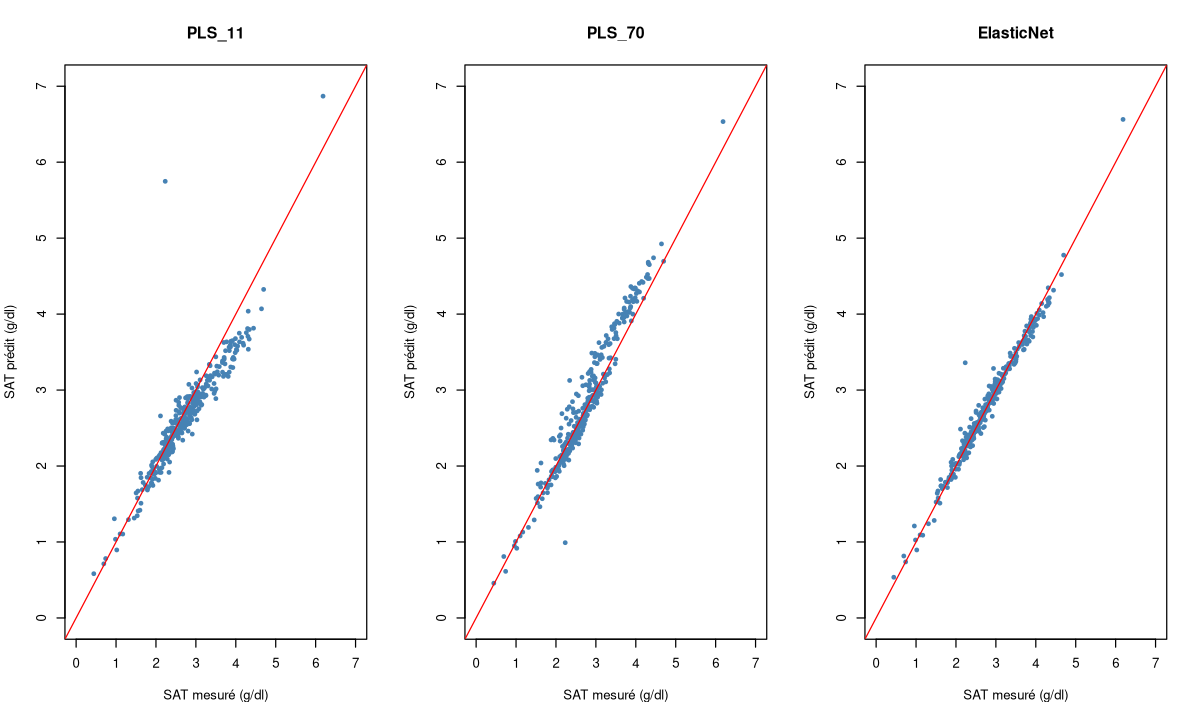

In [15]:
par(mfrow = c(1, 3))
for (m in c("PLS_11", "PLS_70", "ElasticNet")) {
  plot(validy, predtotal[[m]], pch = 19, cex = 0.6, col = "steelblue",
       xlab = "SAT mesuré (g/dl)", ylab = "SAT prédit (g/dl)", main = m,
       xlim = c(0, 7), ylim = c(0, 7))
  abline(0, 1, col = "red")
}
par(mfrow = c(1, 1))

Conclusion du Rmd : « *the best model were ElasticNet* » (R² = 0.978, RMSEP = 0.111 g/dl). C'est confirmé par nos calculs, et l'Elastic Net est aussi le modèle le **moins biaisé**.

Mais un résultat doit intriguer : la **PLS à 11 variables latentes**, choisie en validation croisée (R²cv = 0.963), n'obtient que **0.853** en validation externe, moins bien que la PCR à 10 composantes. Sur le graphe, on voit **un point** très mal prédit (environ 2.2 mesuré, plus de 5.5 prédit). La section suivante explique pourquoi.

### Exercice 5.3 : R² « corrélation » ou R² « 1 − SCE résiduelle / SCE totale » ?
Le Rmd calcule le R² de validation comme le **carré de la corrélation** entre observé et prédit. Une autre définition courante est $R^2 = 1 - \frac{\sum (y_i - \hat y_i)^2}{\sum (y_i - \bar y)^2}$.
1. Calcule les deux R² pour chaque colonne de `predtotal`.
2. Pourquoi sont-ils différents ? Lequel est le plus exigeant ?

In [16]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
r2_cor <- sapply(predtotal, function(p) cor(validy, p)^2)
r2_sce <- sapply(predtotal, function(p) 1 - sum((validy - p)^2) / sum((validy - mean(validy))^2))
round(rbind(r2_cor, r2_sce), 4)
```

Le carré de la corrélation mesure seulement si les prédictions sont **alignées** sur une droite avec les observations : il ignore le **biais** et une pente différente de 1. Le R² « 1 − SCE/SCT » compare directement les prédictions aux observations : il est **plus exigeant** (toujours inférieur ou égal ici) et pénalise le biais. L'écart est grand pour la PCR (biais d'environ -0.12) et presque nul pour l'Elastic Net (biais quasi nul).

</details>

### Exercice 5.4 : une PLS plus complexe ?
Calcule les indicateurs de validation de la PLS pour **tous** les nombres de variables latentes de 1 à 70 (utilise `predictionPLS[, 1, k]`) et trace le RMSEP de validation externe en fonction de k, en superposant le RMSE de validation croisée. Les deux courbes ont-elles le même minimum ?

In [17]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
rmsep_ext <- sapply(1:70, function(k) sqrt(mean((predictionPLS[, 1, k] - validy)^2)))
rmse_cvk  <- RMSEP(PLS, estimate = "CV")$val[1, 1, -1]
plot(1:70, rmsep_ext, type = "l", col = "red", lwd = 2, ylim = range(rmsep_ext, rmse_cvk),
     xlab = "Nombre de variables latentes", ylab = "RMSE (g/dl)")
lines(1:70, rmse_cvk, col = "blue", lwd = 2)
legend("topright", c("Validation externe", "Validation croisée"), col = c("red", "blue"), lwd = 2)
which.min(rmsep_ext)
```

L'erreur de validation externe est **toujours au-dessus** de l'erreur de validation croisée (validation interne trop optimiste), et sa courbe est beaucoup plus irrégulière : elle dépend fortement de quelques échantillons difficiles (section 5.3).

</details>

---
## 5.3 Le domaine de prédiction : GH des échantillons à prédire

Le syllabus (§3.5, *Prediction potentiality*) insiste : pour qu'une prédiction soit fiable, les variables explicatives de l'échantillon à prédire doivent être **comprises dans la variabilité** du jeu de calibration. On le vérifie avec la même **distance GH** que pour le nettoyage (partie 2), mais en **projetant** les nouveaux spectres sur l'ACP **de calibration** :

$$D_i = \sqrt{(x_{PCA,i} - \mu_{PCA})^T\, S_{PCA}^{-1}\, (x_{PCA,i} - \mu_{PCA})} \qquad GH_i = D_i^2 / n_{CP}$$

- **GH < 3** : l'échantillon est dans le domaine de calibration, la prédiction peut être faite ;
- **GH > 5** : l'échantillon est **atypique** par rapport à la calibration : spectre mal mesuré, ou variabilité de calibration insuffisante (il faudrait enrichir le jeu de calibration).

> **Fonction R** : `predict(res.pca, newdata)` (FactoMineR) projette de nouveaux individus sur une ACP existante. `$coord` contient leurs coordonnées sur les composantes, calculées avec **les moyennes et écarts-types de la calibration**. `newdata` doit avoir les mêmes colonnes que les données de l'ACP.

In [18]:
proj <- predict(res.pca, newdata = validation[, 3:1062])$coord   # projection sur l'ACP de calibration
GHval <- mahalanobis(proj, center = colMeans(coordPC), cov = cov(coordPC)) / 47
summary(GHval)
data.frame(echantillon = which(GHval > 3), GH = round(GHval[GHval > 3], 2),
           SAT = validy[GHval > 3])

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.5070  0.8345  0.9894  1.3762  1.2487 98.8296 

echantillon,GH,SAT
<int>,<dbl>,<dbl>
64,3.61,1.624859
139,98.83,2.232112


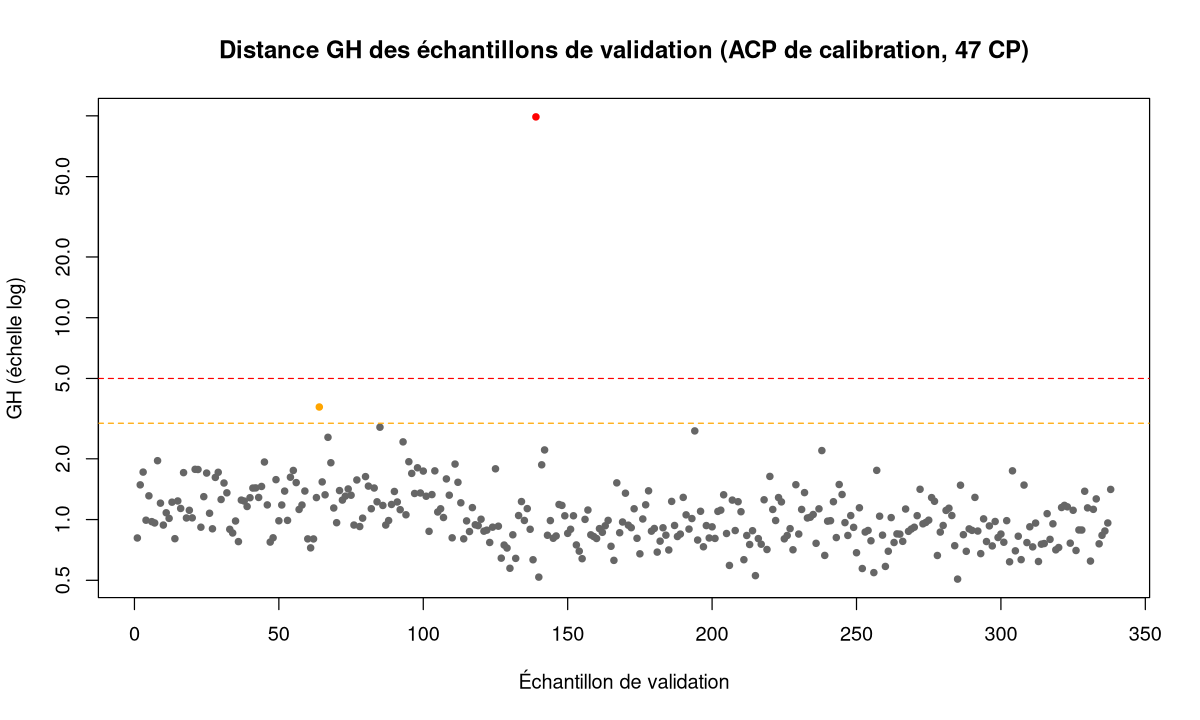

In [19]:
plot(GHval, pch = 19, cex = 0.7, log = "y",
     col = ifelse(GHval > 5, "red", ifelse(GHval > 3, "orange", "grey40")),
     xlab = "Échantillon de validation", ylab = "GH (échelle log)",
     main = "Distance GH des échantillons de validation (ACP de calibration, 47 CP)")
abline(h = c(3, 5), lty = 2, col = c("orange", "red"))

L'échantillon **139** a un GH de **98.8** : son spectre est complètement en dehors du domaine de calibration. C'est lui que la PLS à 11 variables latentes prédit à plus de 5.5 g/dl au lieu de 2.2 :

In [20]:
round(predtotal[139, ] - validy[139], 2)          # erreur de chaque modèle sur l'échantillon 139

# Indicateurs recalculés sans les échantillons hors domaine (GH > 3)
ok <- GHval <= 3
kable(t(sapply(predtotal, function(p) perf_val(validy[ok], p[ok]))), digits = 4, align = "c")

,PCR_57,PCR_10,PLS_70,PLS_11,Ridge,Lasso,ElasticNet
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
139,3.3,0.32,-1.24,3.52,2.66,1.69,1.13




|           |   R2   | RMSEP  |  Biais  |  SEP   |  RPD   |
|:----------|:------:|:------:|:-------:|:------:|:------:|
|PCR_57     | 0.9239 | 0.2593 | -0.1319 | 0.2236 | 2.8894 |
|PCR_10     | 0.9083 | 0.2778 | -0.1173 | 0.2522 | 2.6971 |
|PLS_70     | 0.9531 | 0.2150 | 0.0771  | 0.2010 | 3.4845 |
|PLS_11     | 0.9315 | 0.2424 | -0.1191 | 0.2114 | 3.0912 |
|Ridge      | 0.9587 | 0.1892 | -0.0886 | 0.1675 | 3.9586 |
|Lasso      | 0.9775 | 0.1161 | 0.0112  | 0.1157 | 6.4525 |
|ElasticNet | 0.9851 | 0.0921 | -0.0008 | 0.0922 | 8.1362 |

Sans les deux échantillons hors domaine, la PLS à 11 variables latentes remonte à R² = 0.93 et RMSEP = 0.24 g/dl : elle redevient meilleure que la PCR. L'Elastic Net reste le meilleur, et il est aussi le plus **robuste** face à l'échantillon 139 (erreur de 1.1 g/dl contre 3.5 pour la PLS).

> **Attention** : en pratique, on ne retire **pas** un échantillon de validation parce qu'il est mal prédit : ce serait tricher. La bonne démarche, décrite dans le syllabus, est de calculer le GH **avant** de prédire et de signaler (ou refuser) la prédiction des échantillons hors domaine. Dans un rapport, on présente donc les deux tableaux, en expliquant pourquoi.

### Exercice 5.5 : le spectre de l'échantillon 139
Superpose sur un même graphe le **spectre moyen de calibration** (`colMeans(newX)`) et le spectre de l'échantillon de validation 139. Où se situent les différences ?

In [21]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
plot(colMeans(newX), type = "l", lwd = 2, ylim = range(colMeans(newX), unlist(validation[139, 3:1062])),
     xlab = "Point spectral", ylab = "Absorbance")
lines(unlist(validation[139, 3:1062]), col = "red")
legend("topright", c("Moyenne calibration", "Validation 139"), col = c("black", "red"), lwd = c(2, 1))
```

Le spectre de l'échantillon 139 s'écarte nettement du spectre moyen dans certaines régions : problème de mesure, ou lait très différent de ceux de la calibration. Dans les deux cas, aucun modèle ne peut prédire de façon fiable un échantillon qu'il n'a « jamais vu ».

</details>

---
## 5.4 Suppression des régions spectrales bruitées (exercice dirigé §7)

### 5.4.1 Le coefficient de variation par point spectral

Au homework 1, on a repéré des **régions bruitées** du spectre grâce au **coefficient de variation** (CV) de chaque point spectral. L'exercice dirigé reprend cette idée : on ne garde que les points spectraux dont le CV est **inférieur à 40 %**.

Le Rmd calcule le CV avec `descr()` de summarytools. Comme `descr()` **réordonne les colonnes par ordre alphabétique** (X1, X10, X100, X1000, X1001…), il faut d'abord renommer les colonnes avec le même nombre de chiffres (X0001…X1060).

In [22]:
spectra <- data.frame(x)
names(spectra) <- sprintf("X%04d", 1:1060)   # X0001 ... X1060 (équivalent du rbind(paste0(...)) du Rmd)
stat <- descr(spectra, stats = "common", transpose = TRUE)   # environ 10 secondes
CV <- (100 / stat$Mean) * stat$Std.Dev
# Même calcul, plus direct et sans réordonnancement :
CV2 <- apply(x, 2, sd) / colMeans(x) * 100
all.equal(unname(CV), unname(CV2))
summary(CV)

[1] TRUE

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
-20468.62    -18.40     13.58    585.73     49.09 433749.51 

In [23]:
X2 <- newX[, CV < 40]
dim(X2)
c(CV_negatifs_gardes = sum(CV < 0), abs_CV_inf_40 = sum(abs(CV) < 40))

[1] 482 604

CV_negatifs_gardes      abs_CV_inf_40 
               336                471

On garde bien **604** points spectraux (le Rmd écrit « *604 spectral features instead of 1090* » : c'est 1 060).

> **Attention** : la condition `CV < 40` **sans valeur absolue** garde **tous** les points dont la moyenne est **négative** (CV négatif), même ceux dont le CV vaut -20 000 % ! Parmi les 604 points conservés, **336** ont un CV négatif. Le même problème existait au homework 1 (`CV <= 50`). Une condition plus cohérente avec l'idée « garder les points peu bruités » serait `abs(CV) < 40`, qui garde 471 points (voir l'exercice 5.6).

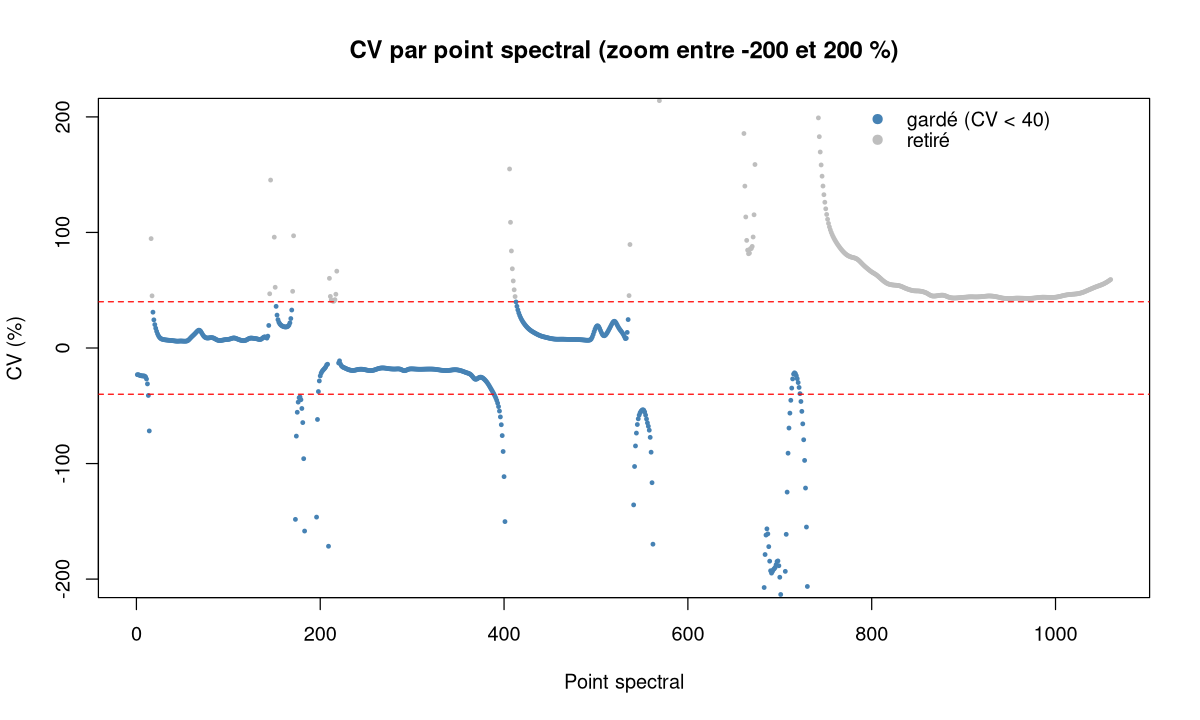

In [24]:
plot(CV, pch = 19, cex = 0.4, ylim = c(-200, 200), col = ifelse(CV < 40, "steelblue", "grey"),
     xlab = "Point spectral", ylab = "CV (%)", main = "CV par point spectral (zoom entre -200 et 200 %)")
abline(h = c(-40, 40), lty = 2, col = "red")
legend("topright", c("gardé (CV < 40)", "retiré"), col = c("steelblue", "grey"), pch = 19, bty = "n")

### 5.4.2 Les modèles sur le spectre réduit

In [25]:
calibration2 <- data.frame(newy, X2)
names(calibration2) <- c("SAT", paste0("SPEC", 1:604))
set.seed(1001)
PCR2 <- pcr(SAT ~ ., data = calibration2, scale = TRUE, center = TRUE, validation = "CV", ncomp = 70)
set.seed(1001)
PLS2 <- plsr(SAT ~ ., data = calibration2, method = "oscorespls", scale = TRUE, center = TRUE,
             validation = "CV", ncomp = 70)

Le Rmd construit pour ces deux modèles le même tableau qu'en partie 4 (« robustness diff » et « accuracy diff »). Mais il contient **deux erreurs** :

> **Attention** : bugs du Rmd au §7
> 1. Tableau de la **PCR2** : les colonnes R² viennent bien de `R2(PCR2)`, mais les colonnes RMSE réutilisent l'objet `RMSEP` du **PLS du §4** (jamais recalculé).
> 2. Tableau de la **PLS2** : il est calculé avec `R2(PLS, "all")`, donc avec la PLS **sur le spectre complet** du §4, et non avec `PLS2`. Le tableau affiché est identique à celui du §4 : la conclusion « *first minimum value at ncomp = 11* » ne concerne donc pas PLS2.
>
> On écrit une fonction qui calcule toujours le tableau à partir **du bon modèle**.

In [26]:
tab_perf <- function(mod, k = 20) {
  r2 <- R2(mod, "all")$val; rm <- RMSEP(mod, "all")$val
  data.frame(R2_calib = 100 * r2[1, 1, ], R2_valid = 100 * r2[2, 1, ],
             RMSEP_calib = rm[1, 1, ], RMSEP_valid = rm[2, 1, ],
             "Robustness diff" = r2[1, 1, ] - r2[2, 1, ],
             "Accuracy diff" = c(0, diff(r2[2, 1, ])), check.names = FALSE)[1:k, ]
}
kable(tab_perf(PCR2), digits = 3, align = "c", caption = "PCR2 (604 points spectraux), tableau corrigé")



Table: PCR2 (604 points spectraux), tableau corrigé

|            | R2_calib | R2_valid | RMSEP_calib | RMSEP_valid | Robustness diff | Accuracy diff |
|:-----------|:--------:|:--------:|:-----------:|:-----------:|:---------------:|:-------------:|
|(Intercept) |  0.000   |  -0.416  |    0.853    |    0.854    |      0.004      |     0.000     |
|1 comps     |  81.279  |  81.152  |    0.369    |    0.370    |      0.001      |     0.816     |
|2 comps     |  83.109  |  82.791  |    0.350    |    0.354    |      0.003      |     0.016     |
|3 comps     |  89.227  |  89.084  |    0.280    |    0.282    |      0.001      |     0.063     |
|4 comps     |  91.361  |  91.178  |    0.251    |    0.253    |      0.002      |     0.021     |
|5 comps     |  92.116  |  91.875  |    0.239    |    0.243    |      0.002      |     0.007     |
|6 comps     |  92.590  |  92.275  |    0.232    |    0.237    |      0.003      |     0.004     |
|7 comps     |  92.591  |  92.308  |    0.232    |    

In [27]:
kable(tab_perf(PLS2), digits = 3, align = "c", caption = "PLS2 (604 points spectraux), tableau corrigé")



Table: PLS2 (604 points spectraux), tableau corrigé

|            | R2_calib | R2_valid | RMSEP_calib | RMSEP_valid | Robustness diff | Accuracy diff |
|:-----------|:--------:|:--------:|:-----------:|:-----------:|:---------------:|:-------------:|
|(Intercept) |  0.000   |  -0.416  |    0.853    |    0.854    |      0.004      |     0.000     |
|1 comps     |  84.958  |  84.774  |    0.331    |    0.333    |      0.002      |     0.852     |
|2 comps     |  90.669  |  90.382  |    0.260    |    0.264    |      0.003      |     0.056     |
|3 comps     |  92.491  |  92.224  |    0.234    |    0.238    |      0.003      |     0.018     |
|4 comps     |  93.464  |  93.066  |    0.218    |    0.225    |      0.004      |     0.008     |
|5 comps     |  94.698  |  94.293  |    0.196    |    0.204    |      0.004      |     0.012     |
|6 comps     |  95.803  |  95.279  |    0.175    |    0.185    |      0.005      |     0.010     |
|7 comps     |  96.502  |  96.004  |    0.159    |    

Lecture corrigée :

- **PCR2** : le gain devient négligeable après **6** composantes (+0.004 de R²cv pour la 6e, 0 pour la 7e) : on retrouve le choix du Rmd (6), qui reposait sur la bonne colonne R².
- **PLS2** : le gain de R²cv reste de quelques millièmes jusqu'à 20 variables latentes, sans « coude » net. Le choix de 11 variables latentes du Rmd n'est pas justifié par **ce** tableau ; on le garde pour reproduire la comparaison, mais un choix entre 8 et 16 serait tout aussi défendable. Avec 11 VL : R²cv = 97.1 %, RMSEcv = 0.146 g/dl, mieux que sur le spectre complet (0.165).

In [28]:
set.seed(1001)
Ridge2 <- cv.glmnet(as.matrix(X2), newy, standardize = TRUE, alpha = 0, lambda = grid, family = "gaussian")
set.seed(1001)
Lasso2 <- cv.glmnet(as.matrix(X2), newy, standardize = TRUE, alpha = 1, lambda = grid, family = "gaussian")
set.seed(1001)
Elastic2 <- cv.glmnet(as.matrix(X2), newy, standardize = TRUE, alpha = 0.5, lambda = grid, family = "gaussian")
kable(rbind(lam(Ridge2, "Ridge"), lam(Lasso2, "Lasso"), lam(Elastic2, "ElasticNet")),
      align = "c", row.names = FALSE)



|   Model    | Lambda.min | Var.min | Lambda.1se | Var.1se |
|:----------:|:----------:|:-------:|:----------:|:-------:|
|   Ridge    |   1e-05    |   604   |   1e-03    |   604   |
|   Lasso    |   1e-05    |   517   |   1e-04    |   275   |
| ElasticNet |   1e-05    |   562   |   1e-04    |   388   |

Comme dans le Rmd : `lambda.1se` = 0.001 pour le Ridge (604 variables), 1e-04 pour le Lasso (275 variables) et l'Elastic Net (388 variables).

### 5.4.3 Validation externe sur le spectre réduit

Les spectres de validation doivent subir **exactement la même sélection** de points spectraux (même vecteur `CV`, calculé sur la calibration).

In [29]:
validspectra2 <- validspectra[, CV < 40]
names(validspectra2) <- paste0("SPEC", 1:604)
predictionPCR2 <- predict(PCR2, newdata = validspectra2)
predictionPLS2 <- predict(PLS2, newdata = validspectra2)
predtotal2 <- data.frame(
  PCR_6  = predictionPCR2[, , 6],  PCR_16 = predictionPCR2[, , 16],
  PLS_11 = predictionPLS2[, , 11], PLS_16 = predictionPLS2[, , 16],   # le Rmd nomme à tort "PLS_6" la colonne à 11 VL
  Ridge  = predict(Ridge2, newx = as.matrix(validspectra2), s = 0.001)[, 1],
  Lasso  = predict(Lasso2, newx = as.matrix(validspectra2), s = 0.0001)[, 1],
  ElasticNet = predict(Elastic2, newx = as.matrix(validspectra2), s = 0.0001)[, 1])
resultfin2 <- t(sapply(predtotal2, function(p) perf_val(validy, p)))
kable(resultfin2, digits = 4, align = "c")



|           |   R2   | RMSEP  |  Biais  |  SEP   |  RPD   |
|:----------|:------:|:------:|:-------:|:------:|:------:|
|PCR_6      | 0.9063 | 0.2842 | -0.1265 | 0.2549 | 2.6386 |
|PCR_16     | 0.8928 | 0.2838 | -0.1255 | 0.2549 | 2.6432 |
|PLS_11     | 0.9209 | 0.2295 | -0.0755 | 0.2170 | 3.2687 |
|PLS_16     | 0.9695 | 0.1509 | 0.0749  | 0.1312 | 4.9701 |
|Ridge      | 0.9663 | 0.1980 | 0.1164  | 0.1604 | 3.7873 |
|Lasso      | 0.9885 | 0.0822 | 0.0168  | 0.0806 | 9.1218 |
|ElasticNet | 0.9840 | 0.0962 | 0.0160  | 0.0950 | 7.7959 |

On retrouve le tableau final du Rmd (R² et RMSEP), qui conclut : « *This final result confirms the interest of using penalized regressions* ». Le **Lasso** sur le spectre réduit est le meilleur modèle de tout l'exercice : R² = 0.989, RMSEP = **0.082** g/dl.

> **Attention** : dans le Rmd, la colonne à 11 variables latentes de la PLS2 est nommée `PLS_6` (copier-coller du nom de la PCR). On l'a renommée `PLS_11`.

In [30]:
# Effet de la suppression des régions bruitées (RMSEP de validation externe)
comp <- data.frame(
  Modele = c("PLS 11 VL", "PLS 16 VL", "Ridge (1se)", "Lasso (1se)", "Elastic Net (1se)"),
  Spectre_complet = c(perf_val(validy, predtotal$PLS_11)["RMSEP"],
                      perf_val(validy, predictionPLS[, , 16])["RMSEP"],
                      perf_val(validy, predRidge_1se)["RMSEP"],
                      perf_val(validy, predtotal$Lasso)["RMSEP"],
                      perf_val(validy, predtotal$ElasticNet)["RMSEP"]),
  Spectre_CV40 = resultfin2[c("PLS_11", "PLS_16", "Ridge", "Lasso", "ElasticNet"), "RMSEP"])
kable(comp, digits = 4, align = "c")



|           |      Modele       | Spectre_complet | Spectre_CV40 |
|:----------|:-----------------:|:---------------:|:------------:|
|PLS_11     |     PLS 11 VL     |     0.3082      |    0.2295    |
|PLS_16     |     PLS 16 VL     |     0.2044      |    0.1509    |
|Ridge      |    Ridge (1se)    |     0.1736      |    0.1980    |
|Lasso      |    Lasso (1se)    |     0.1478      |    0.0822    |
|ElasticNet | Elastic Net (1se) |     0.1106      |    0.0962    |

Retirer les régions bruitées **améliore nettement la PLS** (0.308 → 0.230 avec 11 VL, 0.204 → 0.151 avec 16 VL), le **Lasso** (0.148 → 0.082) et l'**Elastic Net** (0.111 → 0.096) en validation externe : les points bruités apportent surtout du bruit, que le modèle apprend en calibration et qui ne se généralise pas. Seul le **Ridge** se dégrade un peu (0.174 → 0.198), avec un biais de +0.12 : comme il garde toutes les variables avec de petits coefficients, il profite moins du filtrage. Le Rmd n'avait pas pu le voir, puisqu'il utilisait un mauvais λ pour le Ridge sur le spectre complet.

### Exercice 5.6 : et avec `abs(CV) < 40` ?
Refais la PLS (30 variables latentes suffisent) et le Lasso (même grille, `set.seed(1001)`) en ne gardant que les points spectraux tels que `abs(CV) < 40` (471 points). Calcule les indicateurs de validation externe pour la PLS à 11 et 16 variables latentes et pour le Lasso à `lambda.1se`. Le résultat est-il meilleur qu'avec `CV < 40` ?

In [31]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
keep <- abs(CV) < 40
cal3 <- data.frame(SAT = newy, newX[, keep]); names(cal3) <- c("SAT", paste0("SPEC", 1:sum(keep)))
val3 <- validspectra[, keep];                 names(val3) <- names(cal3)[-1]
set.seed(1001)
PLS3 <- plsr(SAT ~ ., data = cal3, method = "oscorespls", scale = TRUE, validation = "CV", ncomp = 30)
set.seed(1001)
Lasso3 <- cv.glmnet(as.matrix(newX[, keep]), newy, alpha = 1, lambda = grid)
p3 <- data.frame(PLS_11 = predict(PLS3, newdata = val3)[, 1, 11],
                 PLS_16 = predict(PLS3, newdata = val3)[, 1, 16],
                 Lasso  = predict(Lasso3, newx = as.matrix(val3), s = "lambda.1se")[, 1])
t(sapply(p3, function(p) perf_val(validy, p)))
```

Résultats obtenus : PLS à 11 VL, R² = 0.970 et RMSEP = 0.205 g/dl (mieux qu'avec `CV < 40`) ; Lasso, R² = 0.968 et RMSEP = 0.163 g/dl (moins bien). Il n'y a pas de règle universelle : le seuil et la façon de filtrer sont des **paramètres** de la démarche, à choisir… en validation croisée, et non en regardant le jeu de validation externe (sinon celui-ci n'est plus indépendant).

</details>

---
## 5.5 Synthèse : PCR, PLS ou régression pénalisée ?

In [32]:
synthese <- rbind(
  "PCR 10 CP (spectre complet)"    = perf_val(validy, predtotal$PCR_10),
  "PLS 11 VL (spectre complet)"    = perf_val(validy, predtotal$PLS_11),
  "Ridge 1se (spectre complet)"    = perf_val(validy, predRidge_1se),
  "Lasso 1se (spectre complet)"    = perf_val(validy, predtotal$Lasso),
  "Elastic Net 1se (complet)"      = perf_val(validy, predtotal$ElasticNet),
  "PLS 11 VL (CV < 40)"            = perf_val(validy, predtotal2$PLS_11),
  "Lasso 1se (CV < 40)"            = perf_val(validy, predtotal2$Lasso),
  "Elastic Net 1se (CV < 40)"      = perf_val(validy, predtotal2$ElasticNet))
kable(synthese, digits = 3, align = "c")



|                            |  R2   | RMSEP | Biais  |  SEP  |  RPD  |
|:---------------------------|:-----:|:-----:|:------:|:-----:|:-----:|
|PCR 10 CP (spectre complet) | 0.906 | 0.279 | -0.117 | 0.253 | 2.690 |
|PLS 11 VL (spectre complet) | 0.853 | 0.308 | -0.108 | 0.289 | 2.433 |
|Ridge 1se (spectre complet) | 0.956 | 0.174 | 0.066  | 0.161 | 4.319 |
|Lasso 1se (spectre complet) | 0.962 | 0.148 | 0.016  | 0.147 | 5.074 |
|Elastic Net 1se (complet)   | 0.978 | 0.111 | 0.003  | 0.111 | 6.784 |
|PLS 11 VL (CV < 40)         | 0.921 | 0.229 | -0.075 | 0.217 | 3.269 |
|Lasso 1se (CV < 40)         | 0.988 | 0.082 | 0.017  | 0.081 | 9.122 |
|Elastic Net 1se (CV < 40)   | 0.984 | 0.096 | 0.016  | 0.095 | 7.796 |

| Critère | PCR | PLS | Régressions pénalisées |
|---|---|---|---|
| Gère la colinéarité et $n < p$ | oui (composantes orthogonales) | oui (variables latentes orthogonales) | oui (pénalité) |
| Utilise y pour réduire la dimension | **non** | **oui** | sans objet (pas de réduction : pénalité sur les coefficients) |
| Parcimonie | 10 composantes | 11 variables latentes | des centaines de coefficients (Lasso : sélection de variables) |
| Paramètre à régler | nombre de CP | nombre de VL | λ (et α) |
| Performance ici (validation externe) | la plus faible | moyenne, sensible aux échantillons hors domaine | **la meilleure** (Lasso, Elastic Net) |
| Interprétation | via les vecteurs propres | via $w^*$, corrélations, coefficients | coefficients directs (Lasso : variables sélectionnées) |

Points à retenir de l'exercice :

1. La **validation croisée** est indispensable pour régler les modèles, mais elle est **optimiste** : seule une **validation externe** mesure vraiment la capacité de généralisation.
2. Sur ces données, les régressions pénalisées (Lasso, Elastic Net) généralisent le mieux, **malgré** leur grand nombre de coefficients ; la crainte de surapprentissage du Rmd ne se confirme pas ici.
3. Avant d'interpréter un mauvais résultat, il faut regarder **quels échantillons** sont mal prédits et vérifier leur **GH** (domaine de prédiction).
4. Le **prétraitement** (ici, retirer les régions bruitées) peut compter autant que le choix de la méthode.
5. Attention à ne pas « optimiser sur le jeu de validation » : si l'on choisit le modèle **parce qu'il** est le meilleur en validation externe, ce jeu sert de fait à la sélection et la performance annoncée devient elle aussi optimiste. Idéalement, il faudrait un troisième jeu (test) jamais utilisé.

---
## Questions de compréhension

**Q1.** Quelle est la différence entre `lambda.min` et `lambda.1se` ? Lequel donne le modèle le plus parcimonieux ?

**Q2.** Pourquoi ne peut-on pas comparer directement `cvm` et le RMSEP d'une PLS ?

**Q3.** Un modèle a un RMSEP de 0.30, un biais de 0.25 et un SEP de 0.17. Que proposes-tu ?

**Q4.** Vrai ou faux : si un échantillon à prédire a un GH de 8, on peut faire confiance à sa prédiction tant que le modèle a un bon R² de validation croisée.

**Q5.** Pourquoi faut-il appliquer **la même** sélection de points spectraux (`CV < 40`) au jeu de validation ? Et pourquoi le CV doit-il être calculé sur la **calibration** seulement ?

<details>
<summary><b>Voir les réponses</b></summary>

**Q1.** `lambda.min` minimise l'erreur moyenne de validation croisée ; `lambda.1se` est le plus grand λ dont l'erreur reste à moins d'une erreur standard du minimum. `lambda.1se` pénalise plus, donc donne le modèle le plus **parcimonieux** (pour le Lasso : moins de variables).

**Q2.** `cvm` est un **MSE** (erreur au carré) : il faut en prendre la **racine** pour obtenir un RMSE comparable.

**Q3.** L'erreur est surtout **systématique** ($0.25^2 + 0.17^2 \approx 0.30^2$) : les prédictions sont décalées en moyenne. Il faut en chercher la cause (population différente, dérive de l'instrument) ; une correction de biais (soustraire 0.25) ferait déjà tomber l'erreur vers 0.17.

**Q4.** Faux. GH > 5 : l'échantillon est hors du domaine de calibration et sa prédiction n'est pas fiable, quelle que soit la qualité du modèle en validation croisée (cf. échantillon 139).

**Q5.** Le modèle a été construit sur des colonnes précises : de nouvelles données doivent avoir **exactement** les mêmes variables, dans le même ordre. Le CV (comme toute étape de prétraitement) fait partie du modèle : le calculer avec les données de validation serait utiliser de l'information du jeu de validation pour construire le modèle (fuite d'information, cf. partie 1).

</details>

---
## Récapitulatif

- `cv.glmnet()` choisit λ par validation croisée k-fold : `cvm` (MSE), `cvsd`, `nzero`, `lambda.min` (erreur minimale) et `lambda.1se` (plus parcimonieux). Toujours vérifier que le minimum n'est pas **au bord de la grille**.
- La **validation externe** (jeu indépendant, jamais utilisé pour construire ni régler le modèle) est le juge final : R², RMSEP, biais, SEP, RPD.
- `predict()` est générique : tableau 3D `[n, 1, ncomp]` pour `pcr`/`plsr` (`newdata`, mêmes noms de colonnes), matrice pour `glmnet` (`newx`, même ordre de colonnes, `s` = λ).
- Avant de prédire, on vérifie le **domaine de prédiction** avec le GH des nouveaux échantillons projetés sur l'ACP de calibration (syllabus §3.5).
- Supprimer les **régions bruitées** améliore la PLS, le Lasso et l'Elastic Net ; sur les acides gras, le **Lasso** sur 604 points spectraux est le meilleur (RMSEP = 0.082 g/dl).
- Erreurs du Rmd corrigées : `s = 0.1` au lieu de `lambda.1se = 0.01` (Ridge), PCR à 57 composantes non justifiée, `cvm` appelé RMSE, tableaux PCR2/PLS2 calculés avec les objets du §4, colonne `PLS_6` pour 11 VL, « 1090 » au lieu de 1 060 variables ; et le filtre `CV < 40` qui garde les CV négatifs.

| Fonction | Rôle |
|---|---|
| `cv.glmnet(x, y, alpha, lambda)` | régression pénalisée avec validation croisée |
| `$lambda.min`, `$lambda.1se`, `$cvm`, `$cvsd`, `$nzero` | résultats de la validation croisée |
| `plot(cvfit)` | erreur de CV en fonction de $\log(\lambda)$ |
| `predict(cvfit, newx, s = "lambda.1se")` | prédictions glmnet |
| `predict(mod_pls, newdata, ncomp)` | prédictions PCR / PLS |
| `coef(cvfit, s)` | coefficients (variables sélectionnées par le Lasso) |
| `predict(res.pca, newdata)$coord` | projection de nouveaux échantillons sur une ACP (FactoMineR) |
| `mahalanobis(coord, center, cov)` | distance (au carré) pour le GH |
| `descr(df, stats = "common", transpose = TRUE)` | statistiques descriptives (attention au réordonnancement des colonnes) |

**Suite** : `06_TP_Homework2_sols.ipynb` : le TP guidé du homework 2 (prédiction de l'azote total des sols par spectrométrie proche infrarouge).